# Байесовские сети
### Датасет: [Deutsche Bank Dataset](https://www.kaggle.com/datasets/saswatsethda/deutsche-bank-dataset)

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


%matplotlib inline
sns.set_theme(style="darkgrid")

df = pd.read_csv("Churn_Modelling.csv", sep=",")

print(df.shape)
print(df.head())

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

(10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4

## 1. Описание данных и предметной области

**Объект** — отдельный клиент банка и его характеристики на момент наблюдения, включая факт ухода из банка. Всего в выборке 10 000 наблюдений и 14 признаков.

**Признаки:**
- `RowNumber`, `CustomerId`, `Surname` — технические идентификаторы клиента (не несут статистической информации о зависимостях).
- `Geography` — страна обслуживания (`France`, `Germany`, `Spain`).
- `Gender` — пол клиента.
- `Age` — возраст клиента (лет).
- `CreditScore` — кредитный рейтинг.
- `Tenure` — срок обслуживания в банке (лет).
- `Balance` — текущий баланс счёта.
- `NumOfProducts` — количество используемых банковских продуктов.
- `HasCrCard` — наличие кредитной карты (0/1).
- `IsActiveMember` — статус активного клиента (0/1).
- `EstimatedSalary` — оценочный годовой доход.
- `Exited` — факт ухода клиента из банка (0 — остался, 1 — ушёл).

**Предварительные гипотезы о зависимостях:**
- Страна обслуживания может влиять как на характер счетов (`Balance`), так и на общий уровень оттока (`Exited`).
- Возраст клиента (`Age`) связан с активностью (`IsActiveMember`) и вероятностью ухода (`Exited`).
- Наличие средств на счёте (`Balance`) связано с набором используемых продуктов (`NumOfProducts`).
- Уход клиента (`Exited`) зависит от совокупности факторов: страны, возраста, числа продуктов и активности.

In [13]:
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "nunique": df.nunique(),
})
print(f"Полных дубликатов строк: {df.duplicated().sum()}")
print(f"Дубликатов CustomerId:   {df['CustomerId'].duplicated().sum()}")
display(summary)

num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"] #описательные статистики числовых признаков
display(df[num_cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))

zero_bal_share = (df["Balance"] == 0).mean()
print(f"Доля клиентов с Balance == 0: {zero_bal_share:.2%}")
print(f"Медиана Balance среди Balance > 0: {df.loc[df['Balance'] > 0, 'Balance'].median():,.2f}")

cat_cols = ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember", "Exited"] #частоты категориальных и дискретных признаков (ищем редкие категории)
for col in cat_cols:
    vc = df[col].value_counts(dropna=False).sort_index()
    pct = (vc / len(df) * 100).round(2)
    print(f"\n {col}")
    display(pd.DataFrame({"count": vc, "share_%": pct}))

Полных дубликатов строк: 0
Дубликатов CustomerId:   0


,dtype,missing,nunique
RowNumber,int64,0,10000
CustomerId,int64,0,10000
Surname,object,0,2932
CreditScore,int64,0,460
Geography,object,0,3
Gender,object,0,2
Age,int64,0,70
Tenure,int64,0,11
Balance,float64,0,6382
NumOfProducts,int64,0,4


,CreditScore,Age,Tenure,Balance,EstimatedSalary
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,100090.24
std,96.65,10.49,2.89,62397.41,57510.49
min,350.00,18.00,0.00,0.00,11.58
10%,521.00,27.00,1.00,0.00,20273.58
25%,584.00,32.00,3.00,0.00,51002.11
50%,652.00,37.00,5.00,97198.54,100193.92
75%,718.00,44.00,7.00,127644.24,149388.25
90%,778.00,53.00,9.00,149244.79,179674.70
max,850.00,92.00,10.00,250898.09,199992.48


Доля клиентов с Balance == 0: 36.17%
Медиана Balance среди Balance > 0: 119,839.69

 Geography


,count,share_%
Geography,,
France,5014,50.14
Germany,2509,25.09
Spain,2477,24.77



 Gender


... (5 outputs left out)


 IsActiveMember


,count,share_%
IsActiveMember,,
0,4849,48.49
1,5151,51.51



 Exited


,count,share_%
Exited,,
0,7963,79.63
1,2037,20.37


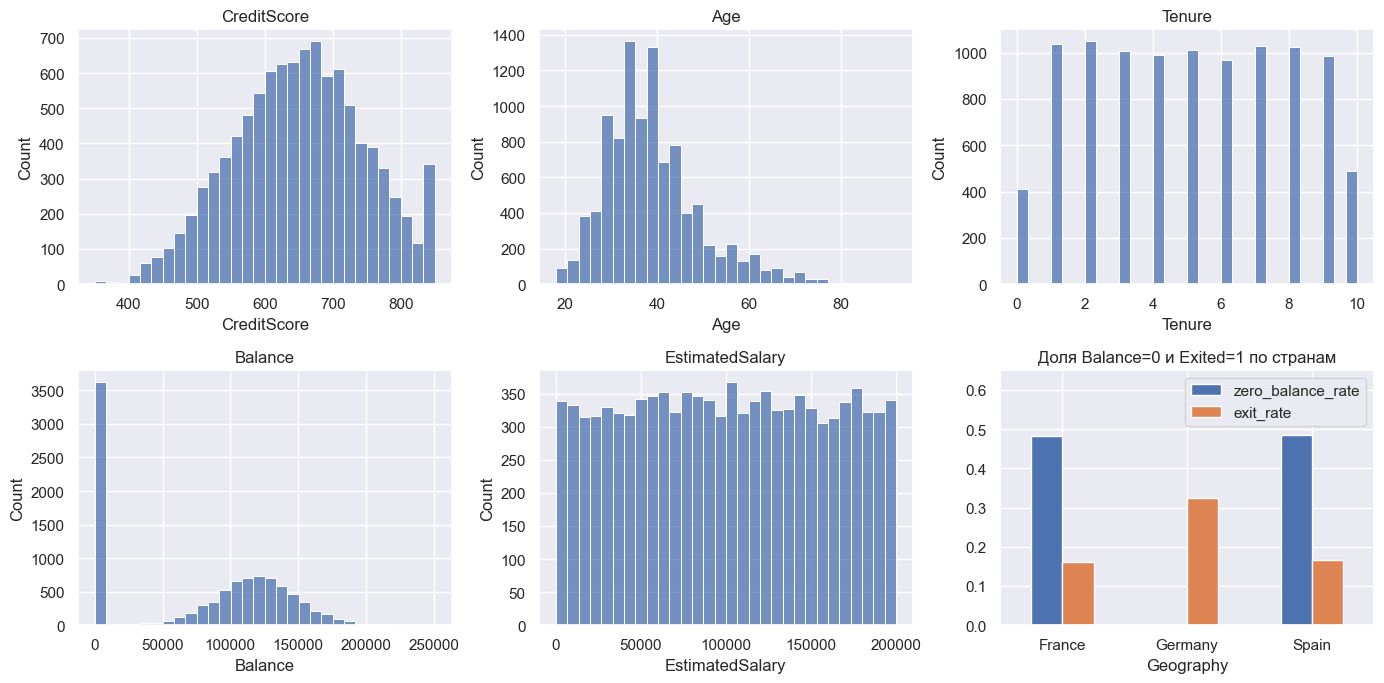

Доля Exited=1 по признакам:


,size,exit_rate
Geography,,
France,5014,0.1615
Germany,2509,0.3244
Spain,2477,0.1667


,size,exit_rate
Gender,,
Female,4543,0.2507
Male,5457,0.1646


,size,exit_rate
NumOfProducts,,
1,5084,0.2771
2,4590,0.0758
3,266,0.8271
4,60,1.0000


,size,exit_rate
HasCrCard,,
0,2945,0.2081
1,7055,0.2018


,size,exit_rate
IsActiveMember,,
0,4849,0.2685
1,5151,0.1427



Сравнение средних и медиан числовых признаков при Exited=0 vs Exited=1:


CreditScore           Age        Tenure          Balance             \
              mean median   mean median   mean median      mean     median   
Exited                                                                       
0           651.85  653.0  37.41   36.0   5.03    5.0  72745.30   92072.68   
1           645.35  646.0  44.84   45.0   4.93    5.0  91108.54  109349.29   

       EstimatedSalary             
                  mean     median  
Exited                             
0             99738.39   99645.04  
1            101465.68  102460.84

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=False, ax=ax)
    ax.set_title(col)

geo_stats = df.groupby("Geography").agg( #доля нулевого баланса и оттока по странам

    n=("Exited", "size"),
    zero_balance_rate=("Balance", lambda s: (s == 0).mean()),
    exit_rate=("Exited", "mean"),
)
geo_stats[["zero_balance_rate", "exit_rate"]].plot(kind="bar", ax=axes.flat[-1], rot=0)
axes.flat[-1].set_title("Доля Balance=0 и Exited=1 по странам")
axes.flat[-1].set_ylim(0, 0.65)
plt.tight_layout()
plt.show()

# Срез: как Exited связан с дискретными и квантильно-разбитыми числовыми признаками
print("Доля Exited=1 по признакам:")
for col in ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember"]:
    display(df.groupby(col)["Exited"].agg(["size", "mean"]).rename(columns={"mean": "exit_rate"}).round(4))

print("\nСравнение средних и медиан числовых признаков при Exited=0 vs Exited=1:")
display(df.groupby("Exited")[num_cols].agg(["mean", "median"]).round(2))

## 2. Подготовка данных и дискретизация

**Итоги первичного анализа и отбор переменных:**
- Пропущенных значений и дубликатов в датасете нет.
- Технические идентификаторы (`RowNumber`, `CustomerId`, `Surname`) исключаются, так как не описывают вероятностные зависимости между свойствами клиента.
- Признаки `CreditScore`, `Tenure`, `EstimatedSalary` и `HasCrCard` не включаются в модель, поскольку их распределения практически не различаются для оставшихся и ушедших клиентов. Признак `Gender` (хотя и даёт различие в оттоке: 25,1% против 16,5%) также оставляем за рамками базового графа, чтобы не удваивать размер таблицы условных вероятностей целевого узла `Exited` и сохранить достаточную наполненность комбинаций родителей.
- В модель отбираем 6 содержательных переменных: `Geo`, `AgeGrp`, `BalGrp`, `ProdGrp`, `Active`, `Exited`.

**Способ и обоснование дискретизации:**
- `Geo` (`Geography`): оставляем исходные 3 категории (`France`, `Germany`, `Spain`) - все хорошо наполнены (от 2 477 до 5 014 наблюдений).
- `AgeGrp` (`Age`, диапазон 18–92, медиана 37): разбиваем на 3 содержательные возрастные группы - `Young` (18–34), `Mid` (35–49) и `Old` (50+). У ушедших клиентов медианный возраст заметно выше (45 против 36), а 3 категории вместо 5+ удерживают компактный размер CPT.
- `BalGrp` (`Balance`): 36,17% клиентов имеют строго нулевой баланс, а среди ненулевых медиана равна 119 839,69. Поэтому стандартное квантильное разбиение некорректно - выделяем отдельный класс `Zero` ($= 0$), а остальные делим по круглому порогу `120 000` (близкому к медиане ненулевых балансов) на `Mid` и `High`.
- `ProdGrp` (`NumOfProducts`): категории `3` (266 строк, 2,66%) и `4` (60 строк, 0,60%) слишком редки для условных таблиц с несколькими родителями и обе имеют экстремально высокий отток (82,7% и 100%). Объединяем их в одну категорию `3+`, получая 3 состояния: `1`, `2`, `3+`.
- `Active` (`IsActiveMember`) и `Exited`: готовые бинарные переменные (`0` и `1`).

In [18]:
from sklearn.model_selection import train_test_split


NODES = ("Geo", "AgeGrp", "BalGrp", "ProdGrp", "Active", "Exited")
STATE_NAMES = {
    "Geo": ["France", "Germany", "Spain"],
    "AgeGrp": ["Young", "Mid", "Old"],
    "BalGrp": ["Zero", "Mid", "High"],
    "ProdGrp": ["1", "2", "3+"],
    "Active": [0, 1],
    "Exited": [0, 1],
}

bn_df = pd.DataFrame({
    "Geo": df["Geography"].astype(str),
    "AgeGrp": pd.cut(df["Age"], bins=[0, 34, 49, 120], labels=["Young", "Mid", "Old"],).astype(str),
    "BalGrp": np.select([df["Balance"] == 0, df["Balance"] <= 120_000], ["Zero", "Mid"], default="High",),
    "ProdGrp": np.where(df["NumOfProducts"] >= 3, "3+", df["NumOfProducts"].astype(str)),
    "Active": df["IsActiveMember"].astype(int),
    "Exited": df["Exited"].astype(int),
})


train_df, test_df = train_test_split(
    bn_df, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=bn_df["Exited"]
)
print(f"Train: {len(train_df):,} объектов | Test: {len(test_df):,} объектов")

# Распределения новых дискретных признаков на всей выборке
print("\nЧастоты дискретизированных переменных:")
for col in ["AgeGrp", "BalGrp", "ProdGrp"]:
    vc = bn_df[col].value_counts().reindex(STATE_NAMES[col])
    pct = (vc / len(bn_df) * 100).round(2)
    display(pd.DataFrame({"count": vc, "share_%": pct, "exit_rate": bn_df.groupby(col)["Exited"].mean().reindex(STATE_NAMES[col]).round(4)}))

Train: 8,000 объектов | Test: 2,000 объектов

Частоты дискретизированных переменных:


,count,share_%,exit_rate
AgeGrp,,,
Young,3679,36.79,0.0788
Mid,4926,49.26,0.2259
Old,1395,13.95,0.4545


,count,share_%,exit_rate
BalGrp,,,
Zero,3617,36.17,0.1382
Mid,3202,32.02,0.2411
High,3181,31.81,0.2405


,count,share_%,exit_rate
ProdGrp,,,
1,5084,50.84,0.2771
2,4590,45.90,0.0758
3+,326,3.26,0.8589


In [19]:
print("1) Таблица сопряжённости Geo x BalGrp (train):")
display(pd.crosstab(train_df["Geo"], train_df["BalGrp"]).reindex(
    index=STATE_NAMES["Geo"], columns=STATE_NAMES["BalGrp"], fill_value=0
))

print("\n2) Таблица сопряжённости BalGrp x ProdGrp (train):")
display(pd.crosstab(train_df["BalGrp"], train_df["ProdGrp"]).reindex(
    index=STATE_NAMES["BalGrp"], columns=STATE_NAMES["ProdGrp"], fill_value=0
))

print("\n3) Таблица сопряжённости AgeGrp x Active (train):")
display(pd.crosstab(train_df["AgeGrp"], train_df["Active"], normalize="index").reindex(
    index=STATE_NAMES["AgeGrp"], columns=STATE_NAMES["Active"]
).round(4))


parent_cols = ["Geo", "AgeGrp", "ProdGrp", "Active"]
full_idx = pd.MultiIndex.from_product(
    [STATE_NAMES[c] for c in parent_cols], names=parent_cols
)
exited_support = ( #4 родителя -> 3*3*3*2 = 54 конфигурации
    train_df.groupby(parent_cols, observed=False)["Exited"]
    .agg(n="size", n_exited="sum", exit_rate="mean")
    .reindex(full_idx)
    .fillna({"n": 0, "n_exited": 0})
)
exited_support["n"] = exited_support["n"].astype(int)
exited_support["n_exited"] = exited_support["n_exited"].astype(int)

print(f"\n4) Поддержка комбинаций родителей для Exited (всего {len(exited_support)} конфигураций):")
print(f"   Пустых (n = 0):           {(exited_support['n'] == 0).sum()}")
print(f"   Редких (1 <= n < 10):     {((exited_support['n'] > 0) & (exited_support['n'] < 10)).sum()}")
print(f"   Достаточных (n >= 10):    {(exited_support['n'] >= 10).sum()}")
print("\nСамые малонаполненные комбинации родителей Exited:")
display(exited_support.sort_values("n").head(12))

1) Таблица сопряжённости Geo x BalGrp (train):


BalGrp,Zero,Mid,High
Geo,,,
France,1930,1030,1033
Germany,0,1013,992
Spain,961,524,517



2) Таблица сопряжённости BalGrp x ProdGrp (train):


ProdGrp,1,2,3+
BalGrp,,,
Zero,723,2077,91
Mid,1670,814,83
High,1678,781,83



3) Таблица сопряжённости AgeGrp x Active (train):


Active,0,1
AgeGrp,,
Young,0.4896,0.5104
Mid,0.5188,0.4812
Old,0.3556,0.6444



4) Поддержка комбинаций родителей для Exited (всего 54 конфигураций):
   Пустых (n = 0):           0
   Редких (1 <= n < 10):     7
   Достаточных (n >= 10):    47

Самые малонаполненные комбинации родителей Exited:


n  n_exited  exit_rate
Geo     AgeGrp ProdGrp Active                         
Spain   Old    3+      1        2         2   1.000000
        Young  3+      1        6         2   0.333333
France  Young  3+      1        8         4   0.500000
Germany Young  3+      0        8         7   0.875000
        Old    3+      1        8         8   1.000000
Spain   Young  3+      0        8         6   0.750000
Germany Young  3+      1        8         5   0.625000
France  Young  3+      0       10         7   0.700000
Spain   Old    3+      0       11        11   1.000000
        Mid    3+      0       12         9   0.750000
France  Old    3+      0       13        13   1.000000
Spain   Mid    3+      1       13        10   0.769231

## 3. Постановка вопросов к вероятностной модели


1. **Прогнозный запрос (вперёд по графу):** как изменится вероятность ухода клиента $P(\text{Exited}=1)$, если известно, что он обслуживается в Германии (`Geo = Germany`) и относится к старшей возрастной группе (`AgeGrp = Old`)?
2. **Диагностический запрос (обратный вывод):** если известно, что клиент ушёл из банка (`Exited = 1`), как меняется вероятность того, что он был неактивным (`Active = 0`), по сравнению с априорной долей неактивных клиентов?
3. **Конкурирующее объяснение (*explaining away*):** если клиент уже ушёл (`Exited = 1`), как дополнительная информация о том, что у него было 3 и более продуктов (`ProdGrp = 3+`), изменит оценку вероятности его неактивности (`Active = 0`)?
4. **Косвенный вывод через цепь:** как знание страны клиента (`Geo = Germany`) меняет распределение количества продуктов (`ProdGrp`) при неизвестном балансе счёта?